# ISN helium direct/indirect beams - plots

Makes all the figures from the data in `data/` (run `bash scripts/run_all.sh` first).

Idea: ln(F_ind/F_dir) = const - β₀ (⟨X⟩_ind - ⟨X⟩_dir), so the beam ratio depends on the
ionization rate but not on the density (or the detector efficiency).

In [14]:
import json
from pathlib import Path
import sys

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

REPO = Path.cwd().resolve()
if REPO.name == "notebooks":
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))

import isnhe
from isnhe import (InflowParams, angular_distance, effective_exposure,
                   log_interp_beta, poisson_deviance, scan_circle,
                   SkyGrid)
from isnhe.constants import GM_SUN, AU_KM

DATA, FIGS = REPO / "data", REPO / "figures"
FIGS.mkdir(exist_ok=True)

# plot style
C_DIR, C_IND, C_ALT = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "lines.linewidth": 2.0, "legend.frameon": False,
})

def save(fig, name):
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight")
    fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight")

# earth longitude <-> date (rough)
def earth_longitude_on(dates):
    jd0 = np.datetime64("2000-01-01T12:00")
    n = (dates - jd0) / np.timedelta64(1, "D")
    L = 280.460 + 0.9856474 * n
    g = np.deg2rad(357.528 + 0.9856003 * n)
    lam_sun = L + 1.915 * np.sin(g) + 0.020 * np.sin(2 * g)
    return (lam_sun + 180.0) % 360.0

MONTHS = np.arange("2026-01", "2027-01", dtype="datetime64[M]").astype("datetime64[m]")
MONTH_LON = earth_longitude_on(MONTHS)
MONTH_LBL = [str(m.astype(object).strftime("%b")) for m in MONTHS.astype("datetime64[D]")]

def add_month_axis(ax):
    top = ax.secondary_xaxis("top")
    top.set_xticks(MONTH_LON, MONTH_LBL)
    top.tick_params(colors=INK2, labelsize=8)
    return top

# load data
ann = np.load(DATA / "annual_beams.npz")
meta = json.loads(str(ann["meta"]))
P = InflowParams(**meta["params"])
L, B = ann["obs_lons"], ann["betas"]
EMINS = ann["emins"]
Fd_all, Fi_all = ann["F_dir"], ann["F_ind"]     # (emin, lon, beta)
Fd, Fi = Fd_all[0], Fi_all[0]                    # no energy threshold

BETA_MODEL = 1.0e-7          # model (TIMED/F10.7-like) rate at 1 au, s^-1
ENH = 1.43                   # Antonik et al. (2025): SWAP / model
BETA_ENH = ENH * BETA_MODEL
LON_DIR, LON_IND = 130.0, 30.0   # reference seasons (Feb: direct; late Oct: indirect)

def at_lon(table, lon):
    i = int(np.argmin(np.abs(((L - lon) + 180) % 360 - 180)))
    return table[i]

print(f"inflow parameters: {P}")
print(f"observer longitudes: {L.size} ({L[1]-L[0]} deg step), betas: {B.min():.1e}..{B.max():.1e}")

inflow parameters: InflowParams(density=0.015, speed=25.4, lon=255.7, lat=5.1, temperature=7500.0)
observer longitudes: 144 (2.5 deg step), betas: 0.0e+00..3.0e-07


## Fig 1 - trajectories

Cold model sketch of the direct and indirect orbits reaching Earth.

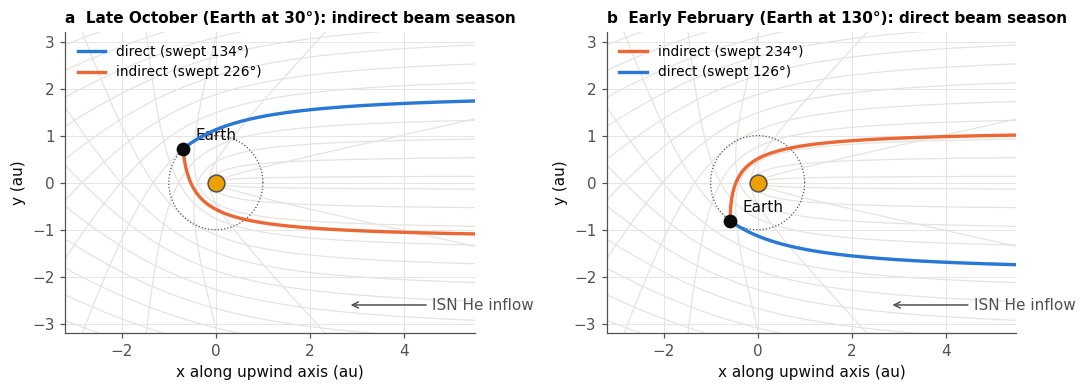

In [15]:
u = P.speed
Lg = GM_SUN / AU_KM / u**2          # GM/u^2 in au

def impact_parameters(r, psi):
    s = r * np.sin(psi) / 2
    root = np.sqrt(s**2 + Lg * r * (1 - np.cos(psi)))
    return s + root, s - root          # b > 0 (counter-clockwise), b < 0 (clockwise)

def trajectory(b, psi_end=None, n=2000):
    # 1/r = (L/b^2)(1 - cos psi) + sin(psi)/b ; psi runs from 0 in the sense of motion
    if b > 0:
        psi = np.linspace(1e-4, 2 * np.pi, n)
    else:
        psi = -np.linspace(1e-4, 2 * np.pi, n)
    inv_r = Lg / b**2 * (1 - np.cos(psi)) + np.sin(psi) / b
    ok = inv_r > 0
    first_bad = np.argmax(~ok) if (~ok).any() else n
    psi, r = psi[:first_bad], 1 / inv_r[:first_bad]
    if psi_end is not None:
        keep = np.abs(psi) <= np.abs(psi_end)
        psi, r = psi[keep], r[keep]
    return r * np.cos(psi), r * np.sin(psi)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.9))
for ax, obs_lon, title in zip(axes, [LON_IND, LON_DIR],
                              ["a  Late October (Earth at 30°): indirect beam season",
                               "b  Early February (Earth at 130°): direct beam season"]):
    for bb in np.concatenate([np.linspace(-5, -0.15, 12), np.linspace(0.15, 5, 12)]):
        x, y = trajectory(bb)
        ax.plot(x, y, color=GRID, lw=0.8, zorder=1)
    th = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), color=INK2, lw=0.8, ls=":", zorder=2)
    ax.plot(0, 0, "o", ms=11, color="#eda100", mec=INK2, zorder=5)
    ax.annotate("ISN He inflow", xy=(2.8, -2.6), xytext=(4.6, -2.6), color=INK2,
                arrowprops=dict(arrowstyle="->", color=INK2), va="center")

    psi_E = np.deg2rad((obs_lon - P.lon) % 360)
    xe, ye = np.cos(psi_E), np.sin(psi_E)
    bp, bm = impact_parameters(1.0, psi_E)
    for b_, psi_end in [(bp, psi_E), (bm, psi_E - 2 * np.pi)]:
        swept = abs(np.rad2deg(psi_end))
        direct = swept < 180
        x, y = trajectory(b_, psi_end)
        col = C_DIR if direct else C_IND
        lbl = f"{'direct' if direct else 'indirect'} (swept {swept:.0f}°)"
        ax.plot(x, y, color=col, lw=2.2, zorder=4, label=lbl)
        assert np.hypot(x[-1] - xe, y[-1] - ye) < 0.02   # orbit really hits Earth
    ax.plot(xe, ye, "o", ms=8, color=INK, zorder=6)
    ax.annotate("Earth", (xe, ye), xytext=(8, 6), textcoords="offset points", color=INK)
    ax.set_xlim(-3.2, 5.5); ax.set_ylim(-3.2, 3.2); ax.set_aspect("equal")
    ax.set_xlabel("x along upwind axis (au)"); ax.set_ylabel("y (au)")
    ax.set_title(title, fontsize=10)
    ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
save(fig, "fig1_trajectories")

## Fig 2 - density at 1 au

Sanity check. Upwind value should be ~0.01 cm⁻³ (Swaczyna+2025).

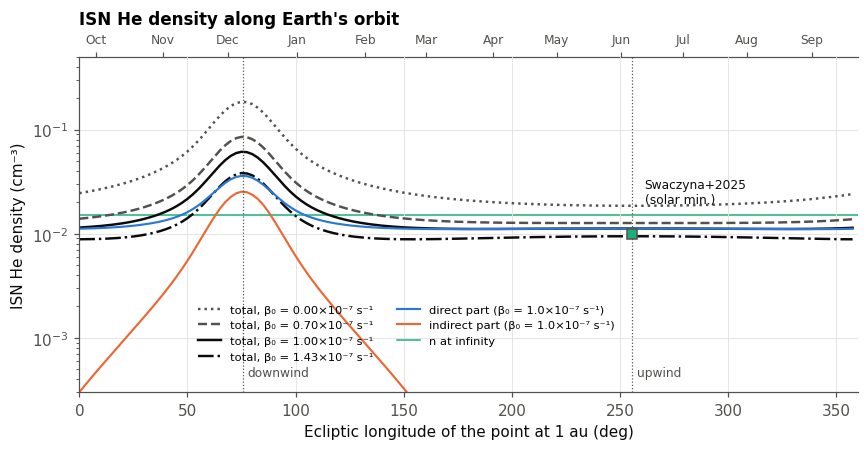

In [16]:
den = np.load(DATA / "density_profile.npz")
lons_d, betas_d = den["lons"], den["betas"]
fig, ax = plt.subplots(figsize=(8, 4.2))
styles = {0.0: (INK2, ":"), 0.7e-7: (INK2, "--"), 1.0e-7: (INK, "-"), 1.43e-7: (INK, "-.")}
for j, b in enumerate(betas_d):
    col, ls = styles.get(round(b, 12), (INK2, "-"))
    ax.plot(lons_d, den["n_all"][:, j], color=col, ls=ls, lw=1.6,
            label=f"total, β₀ = {b*1e7:.2f}×10⁻⁷ s⁻¹")
jm = int(np.argmin(np.abs(betas_d - BETA_MODEL)))
ax.plot(lons_d, den["n_dir"][:, jm], color=C_DIR, lw=1.4, label="direct part (β₀ = 1.0×10⁻⁷ s⁻¹)")
ax.plot(lons_d, den["n_ind"][:, jm], color=C_IND, lw=1.4, label="indirect part (β₀ = 1.0×10⁻⁷ s⁻¹)")
ax.axhline(P.density, color=C_ALT, lw=1.0, zorder=0, label="n at infinity")
ax.set_ylim(3e-4, 0.5)
for x, t in [(P.lon, "upwind"), ((P.lon + 180) % 360, "downwind")]:
    ax.axvline(x, color=INK2, lw=0.8, ls=":")
    ax.text(x + 2, 4e-4, t, color=INK2, fontsize=8, va="bottom")
ax.errorbar([P.lon], [0.010], fmt="s", ms=6, color=C_ALT, mec=INK2, zorder=6)
ax.annotate("Swaczyna+2025\n(solar min.)", (P.lon, 0.010), xytext=(8, 20),
            textcoords="offset points", fontsize=8, color=INK)
ax.set_yscale("log")
ax.set_xlabel("Ecliptic longitude of the point at 1 au (deg)")
ax.set_ylabel("ISN He density (cm⁻³)")
ax.set_xlim(0, 360)
ax.legend(fontsize=7.5, ncol=2, loc="lower center", bbox_to_anchor=(0.42, 0.06))
ax.set_title("ISN He density along Earth's orbit")
add_month_axis(ax)
fig.tight_layout(); save(fig, "fig2_density_1au")

## Fig 3 - sky maps

Total flux in grey, direct (blue) and indirect (orange) contours. Dashed = IBEX-Lo 90° scan circle, solid = pivot angle through the indirect beam.

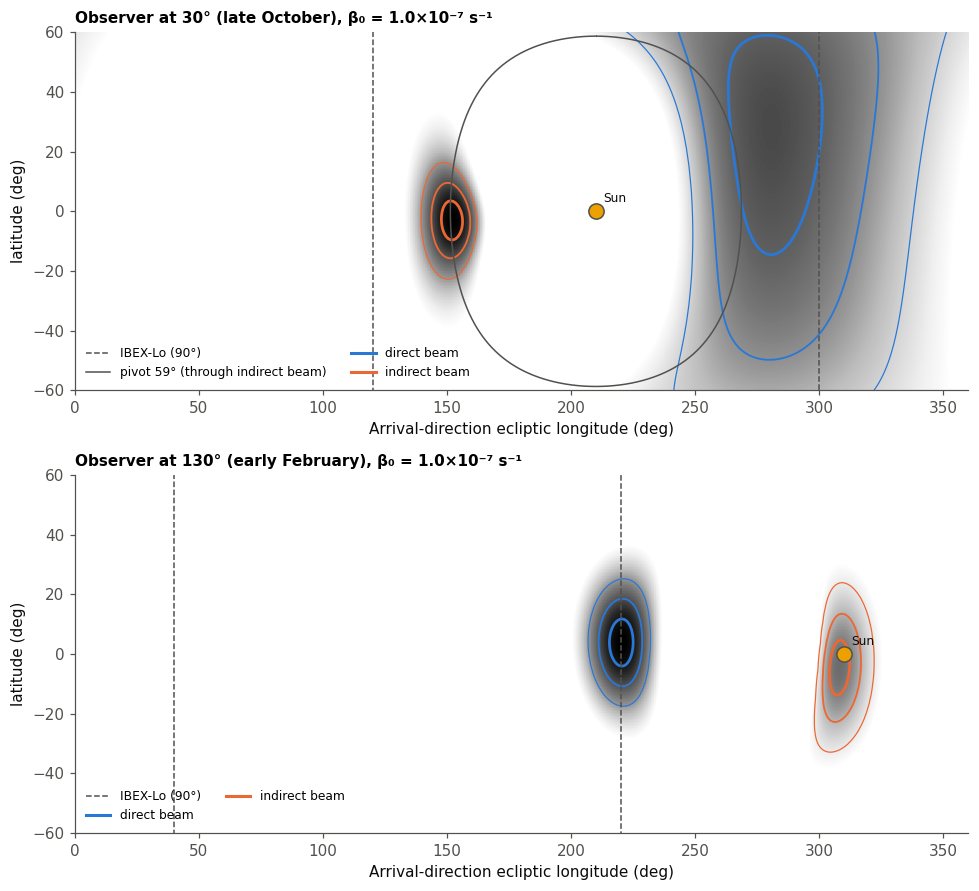

In [17]:
sky = np.load(DATA / "skymaps.npz")
grid = SkyGrid(json.loads(str(sky["meta"]))["grid"]["dang"])
jb = int(np.argmin(np.abs(sky["betas"] - BETA_MODEL)))
show = [LON_IND, LON_DIR]
fig, axes = plt.subplots(2, 1, figsize=(9, 8.2))
for ax, olon in zip(axes, show):
    k = int(np.argmin(np.abs(sky["obs_lons"] - olon)))
    md_, mi_ = sky["direct"][k, jb], sky["indirect"][k, jb]
    tot = md_ + mi_
    ax.imshow(np.where(tot > 0, tot, np.nan), origin="lower", aspect="auto",
              extent=[0, 360, -90, 90], cmap="Greys",
              norm=LogNorm(vmin=tot.max() * 1e-4, vmax=tot.max()))
    for m, col in [(md_, C_DIR), (mi_, C_IND)]:
        ax.contour(grid.lon, grid.lat, m, levels=m.max() * np.array([0.01, 0.1, 0.5]),
                   colors=col, linewidths=[0.8, 1.2, 1.8])
    sun_lon = (olon + 180) % 360
    ax.plot(sun_lon, 0, "o", ms=10, color="#eda100", mec=INK2)
    ax.text(sun_lon + 3, 3, "Sun", fontsize=8, color=INK)
    # scan circles
    circles = [(90.0, "--", "IBEX-Lo (90°)")]
    if olon == LON_IND:
        ci = at_lon(ann["cen_ind"], olon)
        piv = float(angular_distance(sun_lon, 0.0, ci[0], ci[1]))
        circles.append((piv, "-", f"pivot {piv:.0f}° (through indirect beam)"))
    for pv, ls, lab in circles:
        _, clon, clat, _ = scan_circle(tot, grid, olon, pv, n_points=1440)
        jumps = np.where(np.abs(np.diff(clon)) > 10)[0]
        segs = np.split(np.arange(clon.size), jumps + 1)
        for s_ in segs:
            ax.plot(clon[s_], clat[s_], ls=ls, color=INK2, lw=1.0)
        ax.plot([], [], ls=ls, color=INK2, lw=1.0, label=lab)
    ax.plot([], [], color=C_DIR, label="direct beam"); ax.plot([], [], color=C_IND, label="indirect beam")
    ax.set_xlim(0, 360); ax.set_ylim(-60, 60)
    ax.set_xlabel("Arrival-direction ecliptic longitude (deg)")
    ax.set_ylabel("latitude (deg)")
    date = {LON_IND: "late October", LON_DIR: "early February"}[olon]
    ax.set_title(f"Observer at {olon:.0f}° ({date}), β₀ = {sky['betas'][jb]*1e7:.1f}×10⁻⁷ s⁻¹", fontsize=10)
    ax.legend(fontsize=8, loc="lower left", ncol=2)
    ax.grid(False)
fig.tight_layout(); save(fig, "fig3_skymaps")

## Fig 4 - beams over the year

Fluxes, mean energy and angle from the Sun. Grey bands = beams overlap.

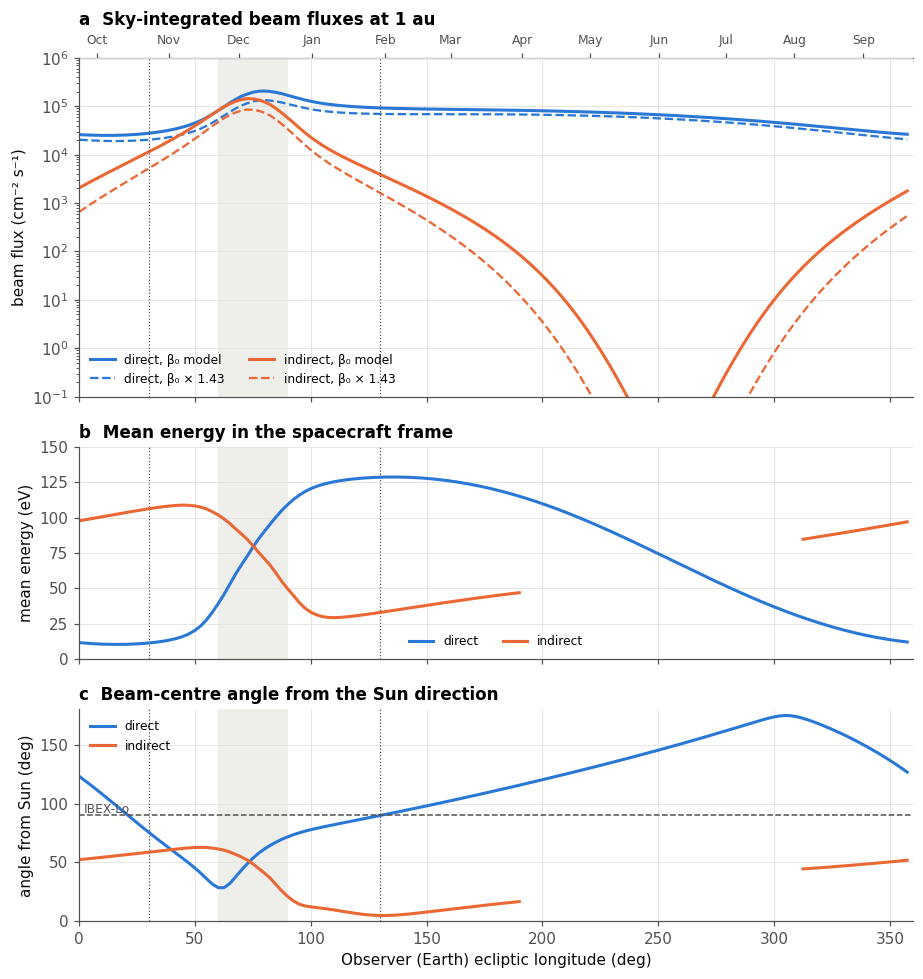

In [18]:
cen_d, cen_i = ann["cen_dir"], ann["cen_ind"]
sep = angular_distance(cen_d[:, 0], cen_d[:, 1], cen_i[:, 0], cen_i[:, 1])
sun_lon = (L + 180) % 360
piv_d = angular_distance(sun_lon, 0 * L, cen_d[:, 0], cen_d[:, 1])
piv_i = angular_distance(sun_lon, 0 * L, cen_i[:, 0], cen_i[:, 1])
blend = sep < (cen_d[:, 2] + cen_i[:, 2])   # centroids closer than the summed RMS widths
# indirect-beam properties are meaningless where the beam is negligible
ind_ok = log_interp_beta(B, Fi, BETA_MODEL) > 1e-3 * log_interp_beta(B, Fd, BETA_MODEL)
masked = lambda a: np.where(ind_ok, a, np.nan)

def shade_blend(ax):
    y0, y1 = ax.get_ylim()
    ax.fill_between(L, y0, y1, where=blend, color=GRID, alpha=0.6, lw=0, zorder=0)
    ax.set_ylim(y0, y1)

fig, axes = plt.subplots(3, 1, figsize=(8.5, 9), sharex=True,
                         gridspec_kw=dict(height_ratios=[1.6, 1, 1]))
ax = axes[0]
for F, col, name in [(Fd, C_DIR, "direct"), (Fi, C_IND, "indirect")]:
    ax.plot(L, log_interp_beta(B, F, BETA_MODEL), color=col, label=f"{name}, β₀ model")
    ax.plot(L, log_interp_beta(B, F, BETA_ENH), color=col, ls="--", lw=1.5,
            label=f"{name}, β₀ × 1.43")
ax.set_yscale("log"); ax.set_ylim(1e-1, 1e6)
ax.set_ylabel("beam flux (cm⁻² s⁻¹)")
ax.legend(fontsize=8, ncol=2, loc="lower left")
ax.set_title("a  Sky-integrated beam fluxes at 1 au")
for x in (LON_DIR, LON_IND):
    for a in axes:
        a.axvline(x, color=INK2, lw=0.8, ls=":")
shade_blend(ax); add_month_axis(ax)

ax = axes[1]
ax.plot(L, ann["E_dir"], color=C_DIR, label="direct")
ax.plot(L, masked(ann["E_ind"]), color=C_IND, label="indirect")
ax.set_ylabel("mean energy (eV)"); ax.set_ylim(0, 150)
ax.legend(fontsize=8, loc="lower center", ncol=2)
ax.set_title("b  Mean energy in the spacecraft frame"); shade_blend(ax)

ax = axes[2]
ax.plot(L, piv_d, color=C_DIR, label="direct")
ax.plot(L, masked(piv_i), color=C_IND, label="indirect")
ax.axhline(90, color=INK2, lw=1, ls="--"); ax.text(2, 92, "IBEX-Lo", fontsize=8, color=INK2)
ax.set_ylim(0, 180); ax.set_ylabel("angle from Sun (deg)")
ax.set_xlabel("Observer (Earth) ecliptic longitude (deg)")
ax.set_title("c  Beam-centre angle from the Sun direction"); ax.legend(fontsize=8, loc="upper left")
shade_blend(ax)
ax.set_xlim(0, 360)
fig.tight_layout(); save(fig, "fig4_annual_beams")

## Fig 5 - exposure and response

H1 = β₀ × 1.43, H2 = n × 1.43. Only the ratio tells them apart.

<X>_dir(130) = 6.661e+06 s, <X>_ind(30) = 1.832e+07 s
responses: {'H1: β₀ × 1.43': [0.751, 0.457, 0.608], 'H2: n × 1.43': [1.43, 1.43, 1.0]}


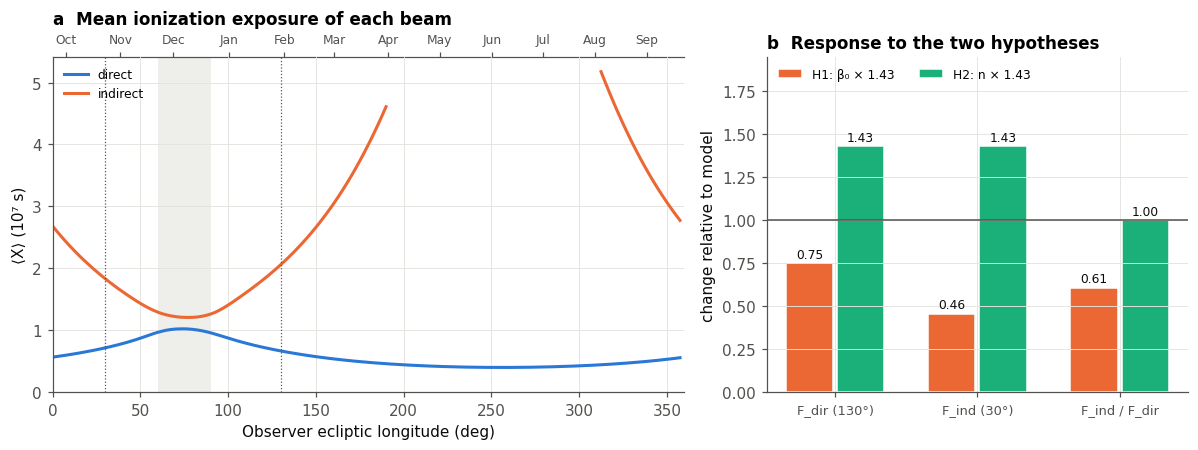

In [19]:
Xd = effective_exposure(B, Fd, BETA_MODEL)
Xi = effective_exposure(B, Fi, BETA_MODEL)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw=dict(width_ratios=[1.5, 1]))
ax = axes[0]
ax.plot(L, Xd / 1e7, color=C_DIR, label="direct")
ax.plot(L, masked(Xi) / 1e7, color=C_IND, label="indirect")
ax.set_ylabel("⟨X⟩ (10⁷ s)"); ax.set_xlabel("Observer ecliptic longitude (deg)")
ax.set_xlim(0, 360); ax.set_ylim(0, None)
for x in (LON_DIR, LON_IND):
    ax.axvline(x, color=INK2, lw=0.8, ls=":")
ax.legend(fontsize=8); ax.set_title("a  Mean ionization exposure of each beam")
y0, y1 = ax.get_ylim()
ax.fill_between(L, y0, y1, where=blend, color=GRID, alpha=0.6, lw=0, zorder=0)
ax.set_ylim(y0, y1)
add_month_axis(ax)

fd0 = log_interp_beta(B, at_lon(Fd, LON_DIR), BETA_MODEL)
fi0 = log_interp_beta(B, at_lon(Fi, LON_IND), BETA_MODEL)
fd1 = log_interp_beta(B, at_lon(Fd, LON_DIR), BETA_ENH)
fi1 = log_interp_beta(B, at_lon(Fi, LON_IND), BETA_ENH)
resp = {"H1: β₀ × 1.43": [fd1 / fd0, fi1 / fi0, (fi1 / fd1) / (fi0 / fd0)],
        "H2: n × 1.43":  [ENH, ENH, 1.0]}
labels = [f"F_dir ({LON_DIR:.0f}°)", f"F_ind ({LON_IND:.0f}°)", "F_ind / F_dir"]
ax = axes[1]
x = np.arange(3); w = 0.36
for k, (name, vals) in enumerate(resp.items()):
    bars = ax.bar(x + (k - 0.5) * w, vals, w * 0.92, color=[C_IND, C_ALT][k],
                  label=name, edgecolor="white", linewidth=1)
    for xi_, v in zip(x + (k - 0.5) * w, vals):
        ax.text(xi_, v + 0.03, f"{v:.2f}", ha="center", fontsize=8, color=INK)
ax.axhline(1, color=INK2, lw=1)
ax.set_xticks(x, labels, fontsize=8.5); ax.set_ylabel("change relative to model")
ax.set_ylim(0, 1.95); ax.legend(fontsize=8, loc="upper left", ncol=2)
ax.set_title("b  Response to the two hypotheses")
fig.tight_layout(); save(fig, "fig5_exposure_response")
print(f"<X>_dir({LON_DIR:.0f}) = {at_lon(Xd, LON_DIR):.3e} s, <X>_ind({LON_IND:.0f}) = {at_lon(Xi, LON_IND):.3e} s")
print("responses:", {k: np.round(v, 3).tolist() for k, v in resp.items()})

## Fig 6 - degeneracy

Fake (noise-free) data from H1 with 10⁴ direct counts. Direct beam alone vs direct + indirect.

indirect counts: 749; beta0 1-sigma range: 1.400-1.460 e-7 s^-1
H2 excluded at delta chi^2 = 199.0 (14.1 sigma, 1 dof)


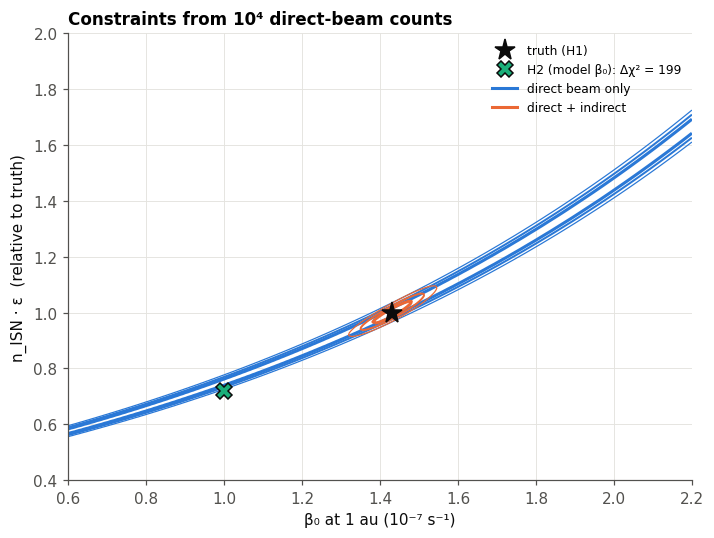

In [20]:
N_DIR_TRUE = 1.0e4
fd_t = log_interp_beta(B, at_lon(Fd, LON_DIR), BETA_ENH)
fi_t = log_interp_beta(B, at_lon(Fi, LON_IND), BETA_ENH)
K = N_DIR_TRUE / fd_t                      # counts per unit flux (same for both seasons)
obs = np.array([N_DIR_TRUE, K * fi_t])

b_grid = np.linspace(0.6e-7, 2.2e-7, 241)
s_grid = np.linspace(0.4, 2.0, 241)        # n*eps relative to truth
fd_g = log_interp_beta(B, at_lon(Fd, LON_DIR), b_grid)
fi_g = log_interp_beta(B, at_lon(Fi, LON_IND), b_grid)
md_counts = K * s_grid[:, None] * fd_g[None, :]
mi_counts = K * s_grid[:, None] * fi_g[None, :]
chi_dir = poisson_deviance(md_counts[..., None], np.array([obs[0]]))
chi_both = poisson_deviance(np.stack([md_counts, mi_counts], -1), obs)
levels = [2.30, 6.18, 11.8]

# H2 point: model beta, n*eps profiled over both beams. For a common Poisson
# normalization the maximum-likelihood scale is sum(observed) / sum(model).
m_h2 = K * np.array([log_interp_beta(B, at_lon(Fd, LON_DIR), BETA_MODEL),
                     log_interp_beta(B, at_lon(Fi, LON_IND), BETA_MODEL)])
s_h2 = obs.sum() / m_h2.sum()
chi_h2 = poisson_deviance(s_h2 * m_h2, obs)

fig, ax = plt.subplots(figsize=(6.6, 5))
ax.contour(b_grid * 1e7, s_grid, chi_dir, levels=levels, colors=C_DIR,
           linewidths=[2, 1.3, 0.8])
ax.contour(b_grid * 1e7, s_grid, chi_both, levels=levels, colors=C_IND,
           linewidths=[2, 1.3, 0.8])
ax.plot(BETA_ENH * 1e7, 1.0, "*", ms=14, color=INK, label="truth (H1)")
ax.plot(BETA_MODEL * 1e7, s_h2, "X", ms=10, color=C_ALT, mec=INK,
        label=f"H2 (model β₀): Δχ² = {chi_h2:.0f}")
ax.plot([], [], color=C_DIR, label="direct beam only")
ax.plot([], [], color=C_IND, label="direct + indirect")
ax.set_xlabel("β₀ at 1 au (10⁻⁷ s⁻¹)")
ax.set_ylabel("n_ISN · ε  (relative to truth)")
ax.legend(fontsize=8, loc="upper right")
ax.set_title("Constraints from 10⁴ direct-beam counts")
fig.tight_layout(); save(fig, "fig6_degeneracy")

# 1-sigma marginal error on beta0 from the combined fit (profile over n*eps)
prof = chi_both.min(axis=0)
inside = b_grid[prof - prof.min() < 1.0]
print(f"indirect counts: {obs[1]:.0f}; beta0 1-sigma range: {inside.min()*1e7:.3f}-{inside.max()*1e7:.3f} e-7 s^-1")
print(f"H2 excluded at delta chi^2 = {chi_h2:.1f} ({np.sqrt(chi_h2):.1f} sigma, 1 dof)")

## Fig 7 - energy threshold

Simple step cut-off in energy.

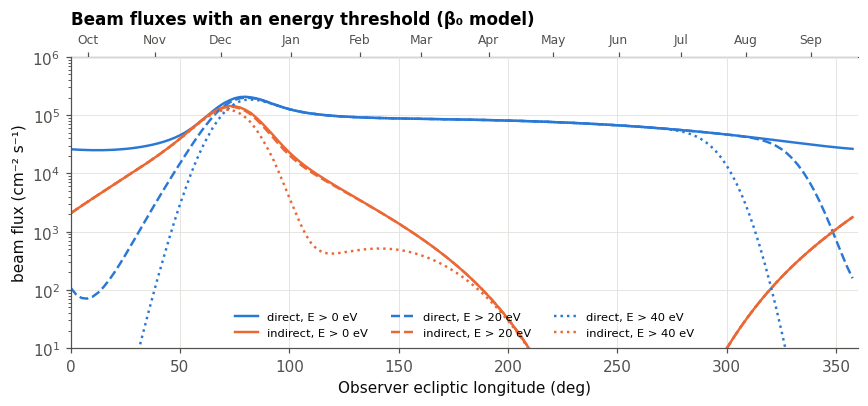

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ls_ = ["-", "--", ":"]
for k, em in enumerate(EMINS):
    ax.plot(L, log_interp_beta(B, Fd_all[k], BETA_MODEL), color=C_DIR, ls=ls_[k % 3], lw=1.6,
            label=f"direct, E > {em:.0f} eV")
    ax.plot(L, log_interp_beta(B, Fi_all[k], BETA_MODEL), color=C_IND, ls=ls_[k % 3], lw=1.6,
            label=f"indirect, E > {em:.0f} eV")
ax.set_yscale("log"); ax.set_ylim(1e1, 1e6); ax.set_xlim(0, 360)
ax.set_xlabel("Observer ecliptic longitude (deg)"); ax.set_ylabel("beam flux (cm⁻² s⁻¹)")
ax.legend(fontsize=7.5, ncol=3, loc="lower center"); add_month_axis(ax)
ax.set_title("Beam fluxes with an energy threshold (β₀ model)")
fig.tight_layout(); save(fig, "fig7_energy_threshold")

## Numbers

In [22]:
rows = [
    ("model beta0 at 1 au", f"{BETA_MODEL:.2e} s^-1"),
    ("upwind density at 1 au", f"{den['n_all'][np.argmin(np.abs(lons_d - P.lon)), jm]:.4f} cm^-3"),
    (f"direct beam energy at {LON_DIR:.0f} deg", f"{at_lon(ann['E_dir'], LON_DIR):.0f} eV"),
    (f"indirect beam energy at {LON_IND:.0f} deg", f"{at_lon(ann['E_ind'], LON_IND):.0f} eV"),
    ("<X> direct / indirect", f"{at_lon(Xd, LON_DIR):.2e} / {at_lon(Xi, LON_IND):.2e} s"),
    ("F_ind/F_dir change for beta0 x 1.43", f"{resp['H1: β₀ × 1.43'][2]:.3f}"),
    ("pivot angle for indirect beam", f"{at_lon(piv_i, LON_IND):.0f} deg"),
]
for a, b in rows:
    print(f"{a:<38} {b}")

model beta0 at 1 au                    1.00e-07 s^-1
upwind density at 1 au                 0.0112 cm^-3
direct beam energy at 130 deg          129 eV
indirect beam energy at 30 deg         106 eV
<X> direct / indirect                  6.66e+06 / 1.83e+07 s
F_ind/F_dir change for beta0 x 1.43    0.608
pivot angle for indirect beam          59 deg
